# 01 · Exploratory data analysis

**Goal of Week 1:** understand the RBA login data well enough to design features and an honest evaluation, *before* writing any model.

Questions this notebook answers:

1. **Label timeline:** how do logins, attack-IP traffic and ATO labels move over time?
2. **Geography and networks:** which countries and ASNs carry attack traffic?
3. **ATO profile:** how do the 141 takeovers differ from normal successful logins?
4. **Novelty preview:** is "first time this user logged in from X" a strong ATO signal?
5. **RTT:** is round-trip time usable, given it is mostly missing?
6. **History depth:** how many logins does a typical user have?

Conventions:
- `real` = all logins **excluding non-account IDs** (see `config.yaml: non_accounts`). That is the population we model.
- ATO questions use only the **labelled window** (before `label_end`), because ATO labels stop on 2020-11-23.
- All numbers are computed on the **full data**, not the 10% sample (the sample has only 20 ATOs).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

from deriddled.config import connect, load_config, path

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

cfg = load_config()
con = connect()
LOGINS = path(cfg["data"]["logins_dir"]).as_posix()
ATO_LABEL_END = cfg["splits"]["ato"]["label_end"]

con.execute(f"CREATE VIEW logins AS SELECT * FROM read_parquet('{LOGINS}/**/*.parquet', hive_partitioning = true)")
con.execute("CREATE VIEW real AS SELECT * FROM logins WHERE NOT is_non_account")
con.execute(f"CREATE VIEW labelled AS SELECT * FROM real WHERE ts < TIMESTAMP '{ATO_LABEL_END}'")

q = lambda sql: con.execute(sql).df()
q("SELECT COUNT(*) AS all_rows, (SELECT COUNT(*) FROM real) AS real_rows, (SELECT COUNT(*) FROM labelled) AS labelled_rows FROM logins")

,all_rows,real_rows,labelled_rows
0,31269264,17169861,12983636


In [2]:
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
LEGIT, ATTACK, ATO = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "figure.dpi": 110,
})

## 1 · Label timeline

Weekly logins, attack-IP share and ATO labels.

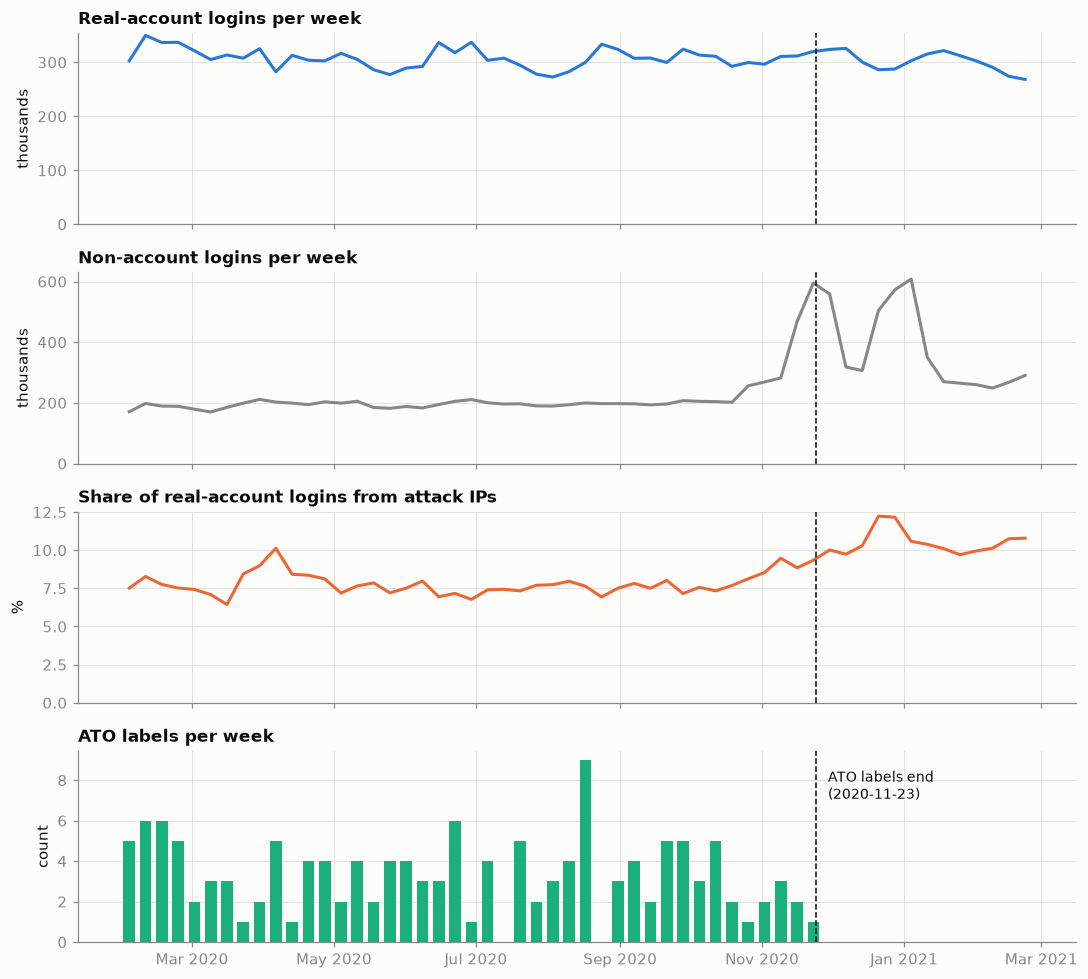

In [3]:
weekly = q('''
    SELECT date_trunc('week', ts)              AS week,
           COUNT(*)                            AS logins,
           100 * AVG(is_attack_ip::INT)        AS attack_ip_pct,
           100 * AVG(login_successful::INT)    AS success_pct,
           SUM(is_ato::INT)                    AS ato
    FROM real
    GROUP BY 1 ORDER BY 1
''')
weekly_non_account = q("SELECT date_trunc('week', ts) AS week, COUNT(*) AS non_account_logins FROM logins WHERE is_non_account GROUP BY 1 ORDER BY 1")

label_end = pd.Timestamp(ATO_LABEL_END)
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
panels = [
    ("Real-account logins per week", weekly["logins"] / 1e3, LEGIT, "thousands", "line"),
    ("Non-account logins per week", weekly_non_account["non_account_logins"] / 1e3, MUTED, "thousands", "line"),
    ("Share of real-account logins from attack IPs", weekly["attack_ip_pct"], ATTACK, "%", "line"),
    ("ATO labels per week", weekly["ato"], ATO, "count", "bar"),
]
for ax, (title, y, colour, unit, kind) in zip(axes, panels):
    x = weekly_non_account["week"] if "Non-account" in title else weekly["week"]
    if kind == "bar":
        ax.bar(x, y, width=5, color=colour)
    else:
        ax.plot(x, y, color=colour)
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.set_ylim(bottom=0)
    ax.axvline(label_end, color=INK, linewidth=1, linestyle="--")
axes[-1].annotate("ATO labels end\n(2020-11-23)", xy=(label_end, axes[-1].get_ylim()[1] * 0.75),
                  xytext=(8, 0), textcoords="offset points", ha="left", fontsize=9, color=INK)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()
plt.show()

In [4]:
q('''
    SELECT month,
           COUNT(*)                                      AS real_logins,
           ROUND(100 * AVG(login_successful::INT), 1)    AS success_pct,
           ROUND(100 * AVG(is_attack_ip::INT), 2)        AS attack_ip_pct,
           SUM(is_ato::INT)                              AS ato,
           ROUND(1e6 * AVG(is_ato::INT), 1)              AS ato_per_million
    FROM real GROUP BY month ORDER BY month
''')

,month,real_logins,success_pct,attack_ip_pct,ato,ato_per_million
0,2020-02,1283042,74.60,7.78,22.00,17.10
1,2020-03,1394422,74.60,7.44,11.00,7.90
2,2020-04,1310656,72.50,8.80,11.00,8.40
3,2020-05,1300725,74.50,7.60,15.00,11.50
4,2020-06,1348733,75.00,7.28,17.00,12.60
5,2020-07,1342770,73.80,7.39,10.00,7.40
6,2020-08,1311178,74.00,7.51,17.00,13.00
7,2020-09,1322672,73.50,7.67,16.00,12.10
8,2020-10,1362770,74.40,7.61,14.00,10.30
9,2020-11,1330275,72.40,9.03,8.00,6.00


**Reading it:**
- Real-account volume is flat (~300k/week); the November jump in total traffic comes from **non-account** logins, i.e. attacks on usernames that don't exist.
- The attack-IP share rises from ~7.5% to ~10.5% from November onwards (prior shift): calibrate on the most recent allowed window.
- ATO labels arrive at a steady 1–5 per week and **stop abruptly** on 23 Nov 2020 while attacks keep rising. This is a labelling cutoff, not a drop in attacks: Dec–Feb is *unlabelled* for ATO.

## 2 · Where does attack traffic come from?

`is_attack_ip` is a property of the IP address, so country/ASN attack rates partly restate the label. Any ASN/IP risk feature must use earlier logins only.

In [5]:
by_country = q('''
    SELECT country,
           COUNT(*)                                        AS logins,
           100 * COUNT(*) / SUM(COUNT(*)) OVER ()          AS pct_of_logins,
           100 * AVG(is_attack_ip::INT)                    AS attack_ip_pct,
           SUM(is_attack_ip::INT)                          AS attack_logins,
           SUM(is_ato::INT)                                AS ato
    FROM real GROUP BY country ORDER BY logins DESC LIMIT 15
''')
by_country

,country,logins,pct_of_logins,attack_ip_pct,attack_logins,ato
0,NO,10707093,62.36,1.19,"127,181.00",10.00
1,US,4047568,23.57,29.19,"1,181,403.00",0.00
2,PL,499263,2.91,10.29,"51,376.00",0.00
3,BR,475263,2.77,1.89,"8,967.00",9.00
4,GB,274350,1.60,4.96,"13,603.00",0.00
5,UA,172202,1.00,2.16,"3,728.00",0.00
6,AU,165685,0.96,11.62,"19,249.00",0.00
7,IN,153234,0.89,4.89,"7,486.00",0.00
8,DE,150020,0.87,3.72,"5,588.00",0.00
9,ID,84498,0.49,6.90,"5,828.00",9.00


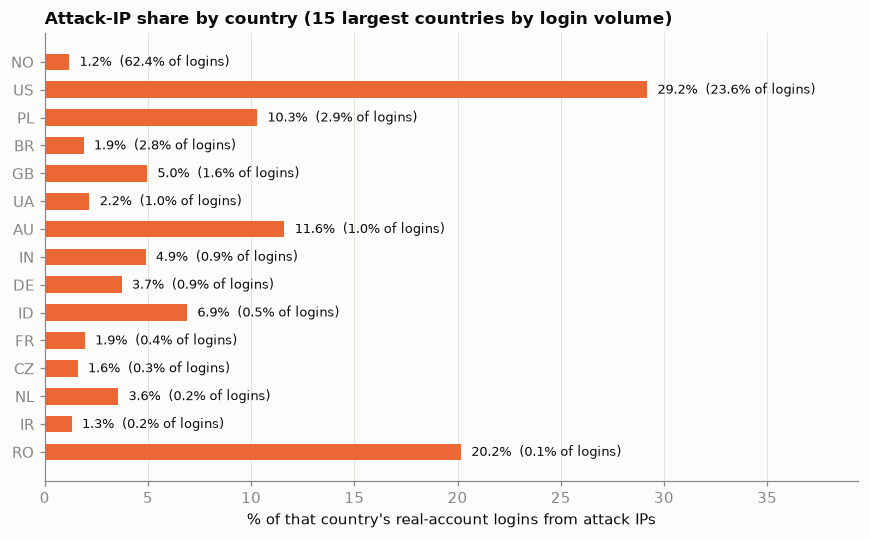

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
d = by_country.iloc[::-1]
ax.barh(d["country"], d["attack_ip_pct"], color=ATTACK, height=0.6)
for y, (v, share) in enumerate(zip(d["attack_ip_pct"], d["pct_of_logins"])):
    ax.text(v + 0.5, y, f"{v:.1f}%  ({share:.1f}% of logins)", va="center", fontsize=8.5, color=INK)
ax.set_title("Attack-IP share by country (15 largest countries by login volume)")
ax.set_xlabel("% of that country's real-account logins from attack IPs")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, d["attack_ip_pct"].max() * 1.35)
fig.tight_layout(); plt.show()

In [7]:
q('''
    WITH c AS (
        SELECT country,
               SUM(is_attack_ip::INT)       AS attack,
               SUM((NOT is_attack_ip)::INT) AS non_attack
        FROM real GROUP BY country
    )
    SELECT country,
           100 * attack / SUM(attack) OVER ()           AS pct_of_attack_logins,
           100 * non_attack / SUM(non_attack) OVER ()   AS pct_of_non_attack_logins,
           (attack / SUM(attack) OVER ()) / NULLIF(non_attack / SUM(non_attack) OVER (), 0) AS lift
    FROM c ORDER BY attack DESC LIMIT 10
''')

,country,pct_of_attack_logins,pct_of_non_attack_logins,lift
0,US,81.74,18.23,4.48
1,NO,8.80,67.28,0.13
2,PL,3.55,2.85,1.25
3,AU,1.33,0.93,1.43
4,GB,0.94,1.66,0.57
5,BR,0.62,2.97,0.21
6,IN,0.52,0.93,0.56
7,ID,0.40,0.50,0.81
8,DE,0.39,0.92,0.42
9,RO,0.29,0.11,2.75


In [8]:
by_asn = q('''
    SELECT asn,
           COUNT(*)                          AS logins,
           100 * AVG(is_attack_ip::INT)      AS attack_ip_pct,
           SUM(is_attack_ip::INT)            AS attack_logins,
           COUNT(DISTINCT user_id)           AS users,
           COUNT(DISTINCT ip)                AS ips,
           mode(country)                     AS main_country
    FROM real GROUP BY asn ORDER BY attack_logins DESC LIMIT 15
''')
by_asn

,asn,logins,attack_ip_pct,attack_logins,users,ips,main_country
0,393398,3501913,29.36,"1,028,327.00",1545802,2512,US
1,398986,121708,78.63,"95,702.00",72631,998,US
2,29695,6490689,0.69,"44,959.00",1380669,951594,NO
3,54903,147677,25.54,"37,713.00",85762,4916,US
4,500021,30565,94.39,"28,850.00",8847,521,NO
5,207674,52360,46.13,"24,154.00",21611,3358,NO
6,60117,137404,12.38,"17,009.00",73299,4350,AU
7,57423,13772,95.82,"13,197.00",3998,211,NO
8,49528,59156,19.28,"11,405.00",19673,733,PL
9,205727,239894,4.12,"9,882.00",63401,11102,PL


In [9]:
q('''
    WITH a AS (SELECT asn, SUM(is_attack_ip::INT) AS attack FROM real GROUP BY asn),
    ranked AS (SELECT attack, ROW_NUMBER() OVER (ORDER BY attack DESC) AS rk,
                      SUM(attack) OVER () AS total FROM a)
    SELECT k, ROUND(100 * SUM(attack) FILTER (WHERE rk <= k) / ANY_VALUE(total), 1) AS pct_of_attack_logins
    FROM ranked, (SELECT unnest([1, 5, 10, 50, 100]) AS k)
    GROUP BY k ORDER BY k
''')

,k,pct_of_attack_logins
0,1,71.10
1,5,85.50
2,10,90.70
3,50,96.40
4,100,97.80


## 3 · What does a takeover look like?

ATO logins vs successful non-ATO logins in the labelled window (140 of 141 ATOs are successful).

In [10]:
profile = q('''
    WITH base AS (
        SELECT CASE WHEN is_ato THEN 'ATO' ELSE 'legit (successful)' END AS grp, *
        FROM labelled
        WHERE login_successful OR is_ato
    )
    SELECT grp,
           COUNT(*)                                         AS logins,
           100 * AVG(is_attack_ip::INT)                     AS attack_ip_pct,
           100 * AVG((country = 'NO')::INT)                 AS norway_pct,
           100 * AVG((device_type = 'mobile')::INT)         AS mobile_pct,
           100 * AVG((device_type = 'desktop')::INT)        AS desktop_pct,
           100 * AVG((rtt_ms IS NOT NULL)::INT)             AS rtt_present_pct,
           100 * AVG((city IS NULL)::INT)                   AS city_missing_pct
    FROM base GROUP BY grp
''').set_index("grp").T
profile["ratio (ATO / legit)"] = profile["ATO"] / profile["legit (successful)"]
profile

grp,ATO,legit (successful),ratio (ATO / legit)
logins,141.00,"9,608,708.00",0.00
attack_ip_pct,54.61,6.03,9.05
norway_pct,7.09,69.69,0.10
mobile_pct,14.18,61.68,0.23
desktop_pct,85.11,34.31,2.48
rtt_present_pct,0.71,7.14,0.10
city_missing_pct,53.19,35.99,1.48


In [11]:
q('''
    SELECT country, COUNT(*) AS ato_logins, ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM labelled WHERE is_ato GROUP BY country ORDER BY ato_logins DESC LIMIT 10
''')

,country,ato_logins,pct
0,RO,79,56.00
1,NO,10,7.10
2,CA,9,6.40
3,BR,9,6.40
4,ID,9,6.40
5,IT,7,5.00
6,DK,5,3.50
7,LV,3,2.10
8,CL,3,2.10
9,CZ,2,1.40


### 3b · One campaign behind most takeovers?

Romania carries 0.1% of logins but **79 of 141 ATOs**. If one campaign dominates train and test labels, a model can memorise its fingerprint and inflate recall, so recall is reported separately for the campaign and for other ATOs.

In [12]:
q('''
    SELECT COUNT(*)                         AS ato,
           COUNT(DISTINCT user_id)          AS victims,
           COUNT(DISTINCT ip)               AS ips,
           COUNT(DISTINCT asn)              AS asns,
           MIN(ts)::DATE                    AS first,
           MAX(ts)::DATE                    AS last,
           ROUND(100 * AVG(is_attack_ip::INT), 1) AS attack_ip_pct
    FROM labelled WHERE is_ato AND country = 'RO'
''')

,ato,victims,ips,asns,first,last,attack_ip_pct
0,79,78,59,27,2020-02-04,2020-11-23,83.50


In [13]:
q('''
    SELECT country = 'RO' AS romania, browser, os, COUNT(*) AS ato
    FROM labelled WHERE is_ato
    GROUP BY ALL ORDER BY ato DESC LIMIT 8
''')

,romania,browser,os,ato
0,True,Chrome 79.0.3945.192.218,Mac OS X 10.14.6,55
1,False,Chrome 79.0.3945.192.218,Mac OS X 10.14.6,33
2,True,Chrome 79.0.3945.192.205,Mac OS X 10.14.6,7
3,True,Chrome Mobile 81.0.4044.1950,Android 5.5.1,4
4,False,Chrome 79.0.3945.192.205,Mac OS X 10.14.6,2
5,False,Chrome 79.0.3945.192.198,Mac OS X 10.14.6,2
6,False,Chrome 69.0.3497.17.20,Mac OS X 10.14.6,2
7,False,Chrome Mobile 81.0.4044.1950,Android 5.5.1,2


In [14]:
from deriddled.splits import split_case
q(f'''
    SELECT {split_case("ato")} AS split,
           SUM((country = 'RO')::INT)  AS romanian_campaign,
           SUM((country <> 'RO')::INT) AS other_ato
    FROM labelled WHERE is_ato GROUP BY 1
    ORDER BY CASE split WHEN 'train' THEN 1 WHEN 'valid' THEN 2 ELSE 3 END
''')

,split,romanian_campaign,other_ato
0,train,44.00,42.00
1,valid,19.00,14.00
2,test,16.00,6.00


**Reading it:** 78 victims over 10 months, 59 IPs on 27 networks, mostly one browser string (`Chrome 79.0.3945.192.218`, `Mac OS X 10.14.6`): likely one actor reusing a tool. It supplies **16 of the 22 test ATOs**.

## 4 · Novelty preview: "first time this user did X"

Point-in-time "first login of this user from this country/ASN/device/IP", for logins where the user has earlier history. Lift = P(new | ATO) / P(new | legit).

In [15]:
novelty = q('''
    WITH w AS (
        SELECT is_ato, login_successful,
               ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY ts, login_id)                       AS nth_login,
               ROW_NUMBER() OVER (PARTITION BY user_id, country ORDER BY ts, login_id) = 1          AS new_country,
               ROW_NUMBER() OVER (PARTITION BY user_id, asn ORDER BY ts, login_id) = 1              AS new_asn,
               ROW_NUMBER() OVER (PARTITION BY user_id, browser, os, device_type
                                  ORDER BY ts, login_id) = 1                                        AS new_device,
               ROW_NUMBER() OVER (PARTITION BY user_id, ip ORDER BY ts, login_id) = 1               AS new_ip
        FROM real
        WHERE ts < TIMESTAMP '%s'
    )
    SELECT CASE WHEN is_ato THEN 'ATO' ELSE 'legit (successful)' END AS grp,
           COUNT(*)                          AS logins,
           100 * AVG(new_country::INT)       AS new_country_pct,
           100 * AVG(new_asn::INT)           AS new_asn_pct,
           100 * AVG(new_device::INT)        AS new_device_pct,
           100 * AVG(new_ip::INT)            AS new_ip_pct,
           100 * AVG((new_country AND new_asn AND new_device)::INT) AS all_three_new_pct
    FROM w
    WHERE nth_login > 1 AND (login_successful OR is_ato)
    GROUP BY grp
''' % ATO_LABEL_END).set_index("grp").T
novelty["lift"] = novelty["ATO"] / novelty["legit (successful)"]
novelty

grp,legit (successful),ATO,lift
logins,"7,408,770.00",93.00,0.00
new_country_pct,0.70,73.12,104.62
new_asn_pct,9.55,79.57,8.33
new_device_pct,36.16,68.82,1.90
new_ip_pct,37.08,88.17,2.38
all_three_new_pct,0.49,64.52,131.92


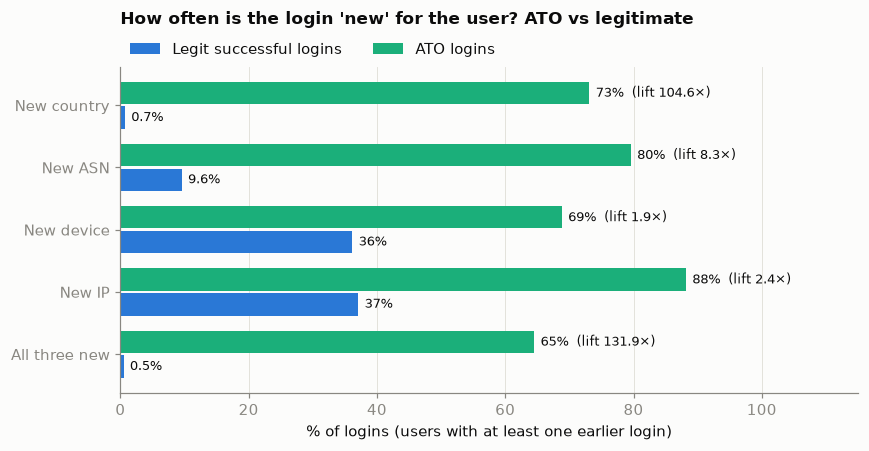

In [16]:
d = novelty.drop(index="logins")
labels = ["New country", "New ASN", "New device", "New IP", "All three new"]
fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(len(d))
ax.barh([i + 0.2 for i in y], d["legit (successful)"], height=0.36, color=LEGIT, label="Legit successful logins")
ax.barh([i - 0.2 for i in y], d["ATO"], height=0.36, color=ATO, label="ATO logins")
for i, (a, l, lift) in enumerate(zip(d["ATO"], d["legit (successful)"], d["lift"])):
    ax.text(a + 1, i - 0.2, f"{a:.0f}%  (lift {lift:.1f}×)", va="center", fontsize=8.5, color=INK)
    ax.text(l + 1, i + 0.2, f"{l:.1f}%" if l < 10 else f"{l:.0f}%", va="center", fontsize=8.5, color=INK)
ax.set_yticks(list(y), labels)
ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.set_xlabel("% of logins (users with at least one earlier login)")
ax.set_title("How often is the login 'new' for the user? ATO vs legitimate", pad=28)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, borderaxespad=0.2)
fig.tight_layout(); plt.show()

In [17]:
q('''
    WITH w AS (
        SELECT is_ato, login_successful, country,
               ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY ts, login_id)              AS nth_login,
               ROW_NUMBER() OVER (PARTITION BY user_id, country ORDER BY ts, login_id) = 1 AS new_country,
               ROW_NUMBER() OVER (PARTITION BY user_id, asn ORDER BY ts, login_id) = 1     AS new_asn
        FROM real WHERE ts < TIMESTAMP '%s'
    )
    SELECT CASE WHEN is_ato THEN 'ATO (excl. RO)' ELSE 'legit (excl. RO)' END AS grp,
           COUNT(*) AS logins,
           ROUND(100 * AVG(new_country::INT), 2) AS new_country_pct,
           ROUND(100 * AVG(new_asn::INT), 2)     AS new_asn_pct
    FROM w
    WHERE nth_login > 1 AND (login_successful OR is_ato) AND country <> 'RO'
    GROUP BY grp
''' % ATO_LABEL_END)

,grp,logins,new_country_pct,new_asn_pct
0,legit (excl. RO),7402216,0.68,9.54
1,ATO (excl. RO),44,70.45,75.00


**Caveats:**
- Only **93 of 141** ATOs have earlier history; the other 48 are the user's first login in the data (partly left-censoring). Those need population features.
- Lifts rest on 93 positives (44 without Romania): strong signal, not exact values.

## 5 · Round-trip time (RTT)

~96% missing. Presence rate and distribution by group.

In [18]:
q('''
    SELECT CASE WHEN is_ato THEN 'ATO'
                WHEN is_attack_ip THEN 'attack IP'
                ELSE 'legit' END                        AS grp,
           COUNT(*)                                     AS logins,
           100 * AVG((rtt_ms IS NOT NULL)::INT)         AS rtt_present_pct,
           quantile_cont(rtt_ms, 0.25)                  AS p25_ms,
           median(rtt_ms)                               AS median_ms,
           quantile_cont(rtt_ms, 0.75)                  AS p75_ms,
           quantile_cont(rtt_ms, 0.99)                  AS p99_ms
    FROM real GROUP BY grp ORDER BY grp
''')

,grp,logins,rtt_present_pct,p25_ms,median_ms,p75_ms,p99_ms
0,ATO,141,0.71,673.00,673.00,673.00,673.00
1,attack IP,1445277,1.10,474.00,543.00,696.00,"2,866.80"
2,legit,15724443,6.68,471.00,536.00,669.00,"2,394.00"


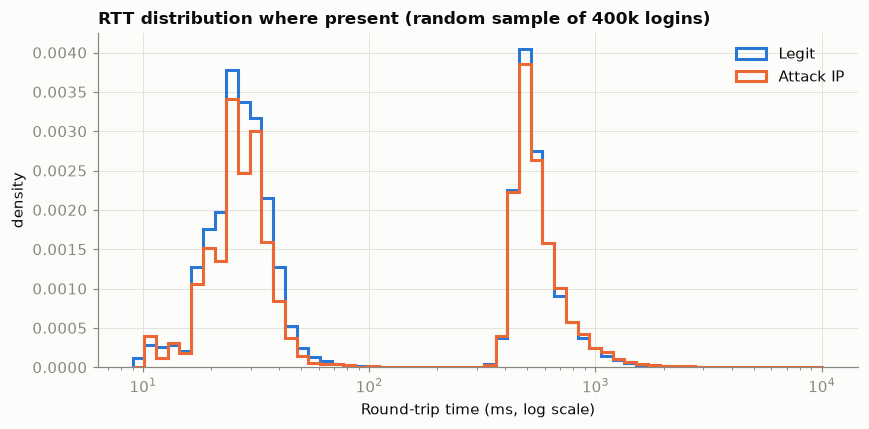

In [19]:
import numpy as np
rtt = q('''
    SELECT * FROM (
        SELECT rtt_ms, is_attack_ip FROM real
        WHERE rtt_ms IS NOT NULL AND rtt_ms > 0 AND NOT is_ato
    ) USING SAMPLE 400000 ROWS (reservoir, 42)
''')
bins = np.logspace(np.log10(max(rtt.rtt_ms.min(), 1)), np.log10(rtt.rtt_ms.quantile(0.999)), 60)
fig, ax = plt.subplots(figsize=(8, 4))
for flag, colour, name in [(False, LEGIT, "Legit"), (True, ATTACK, "Attack IP")]:
    ax.hist(rtt.loc[rtt.is_attack_ip == flag, "rtt_ms"], bins=bins, density=True,
            histtype="step", linewidth=2, color=colour, label=name)
ax.set_xscale("log")
ax.set_xlabel("Round-trip time (ms, log scale)")
ax.set_ylabel("density")
ax.set_title("RTT distribution where present (random sample of 400k logins)")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

**Reading it:** RTT is bimodal (~25 ms and ~500 ms clusters) with near-identical shapes for attack and legit traffic, and only 1 of 141 ATOs has a value. At most, `rtt_present` (6.7% legit vs 1.1% attack) is a weak feature.

## 6 · How much history does a user have?

Logins per user, and how much traffic falls on the new-user path (FR-5: < 3 prior logins).

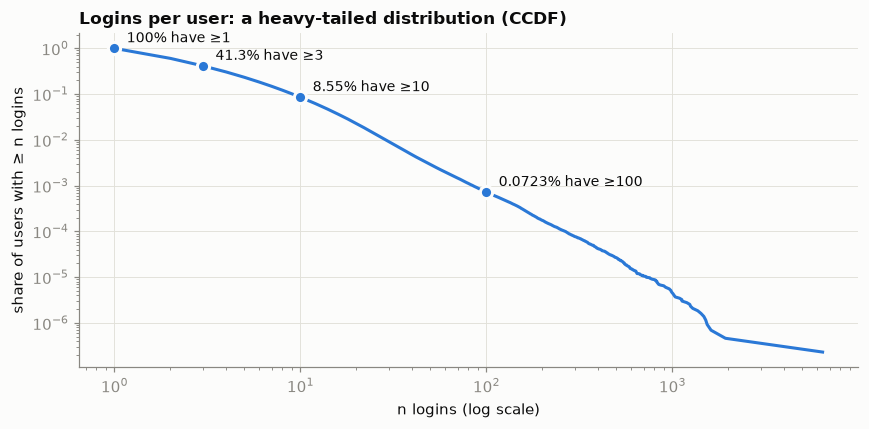

In [20]:
hist = q('''
    SELECT n_logins, COUNT(*) AS users
    FROM (SELECT user_id, COUNT(*) AS n_logins FROM real GROUP BY user_id)
    GROUP BY n_logins ORDER BY n_logins
''')
hist =hist.sort_values("n_logins")
hist["ccdf"] = hist["users"][::-1].cumsum()[::-1] / hist["users"].sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["n_logins"], hist["ccdf"], color=LEGIT)
for n in (1, 3, 10, 100):
    share = hist.loc[hist["n_logins"] >= n, "users"].sum() / hist["users"].sum()
    ax.plot(n, share, "o", color=LEGIT, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{share * 100:.3g}% have ≥{n}", (n, share), xytext=(8, 4), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n logins (log scale)")
ax.set_ylabel("share of users with ≥ n logins")
ax.set_title("Logins per user: a heavy-tailed distribution (CCDF)")
fig.tight_layout(); plt.show()

In [21]:
q('''
    WITH w AS (
        SELECT is_ato, ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY ts, login_id) - 1 AS prior_logins
        FROM real
    )
    SELECT ROUND(100 * AVG((prior_logins < 3)::INT), 1)                              AS pct_logins_new_user_path,
           ROUND(100 * AVG((prior_logins < 3)::INT) FILTER (WHERE is_ato), 1)        AS pct_ato_on_new_user_path,
           SUM((prior_logins = 0)::INT) FILTER (WHERE is_ato)                        AS ato_on_first_ever_login
    FROM w
''')

,pct_logins_new_user_path,pct_ato_on_new_user_path,ato_on_first_ever_login
0,50.50,63.80,48.00


## Takeaways

See `docs/eda_summary.md` for the one-page summary of these results and the decisions they drive.